# Project 2: Concrete Compressive Strength Prediction

## 1. Introduction

Concrete compressive strength is an important property in civil engineering and depends on mixture composition and curing age. The relationship between these variables and concrete strength may be nonlinear.

This project investigates the prediction of concrete compressive strength using eight numerical predictors: cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate, fine aggregate, and curing age.

The analysis aims to explore and prepare the dataset, establish a mean-prediction baseline, compare linear and nonlinear regression approaches, examine prediction residuals, and critically assess whether predictive associations can support causal conclusions about changes in concrete mixtures.

## 2. Exploratory Data Analysis

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("Concrete_Data.csv")

# Display dataset dimensions
print("Dataset dimensions:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display first five observations
display(df.head())

# Inspect data types and missing values
print("\nDataset information:")
df.info()

Dataset dimensions: (1030, 9)

Column names:
['Cement (kg in a m^3 mixture)', 'Blast Furnace Slag (kg in a m^3 mixture)', 'Fly Ash (kg in a m^3 mixture)', 'Water (kg in a m^3 mixture)', 'Superplasticizer (kg in a m^3 mixture)', 'Coarse Aggregate (kg in a m^3 mixture)', 'Fine Aggregate (kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength (MPa, megapascals) ']


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Cement (kg in a m^3 mixture)                       1030 non-null   float64
 1   Blast Furnace Slag (kg in a m^3 mixture)           1030 non-null   float64
 2   Fly Ash (kg in a m^3 mixture)                      1030 non-null   float64
 3   Water (kg in a m^3 mixture)                        1030 non-null   float64
 4   Superplasticizer (kg in a m^3 mixture)             1030 non-null   float64
 5   Coarse Aggregate (kg in a m^3 mixture)             1030 non-null   float64
 6   Fine Aggregate (kg in a m^3 mixture)               1030 non-null   float64
 7   Age (day)                                          1030 non-null   int64  
 8   Concrete compressive strength (MPa, megapascals)   1030 non-null   

In [2]:
# Generating descriptive statistics

display(df.describe().T.round(2))

# Checking missing values
print("Total missing values:", df.isnull().sum().sum())

# Checking duplicate observations
print("Duplicate observations:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
Cement (kg in a m^3 mixture),1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Blast Furnace Slag (kg in a m^3 mixture),1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
Fly Ash (kg in a m^3 mixture),1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water (kg in a m^3 mixture),1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer (kg in a m^3 mixture),1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
Coarse Aggregate (kg in a m^3 mixture),1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
Fine Aggregate (kg in a m^3 mixture),1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age (day),1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
"Concrete compressive strength (MPa, megapascals)",1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


Total missing values: 0
Duplicate observations: 25


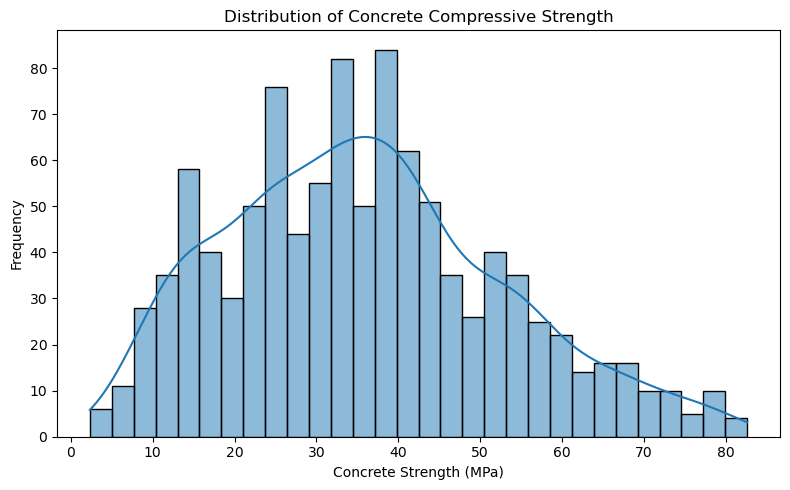

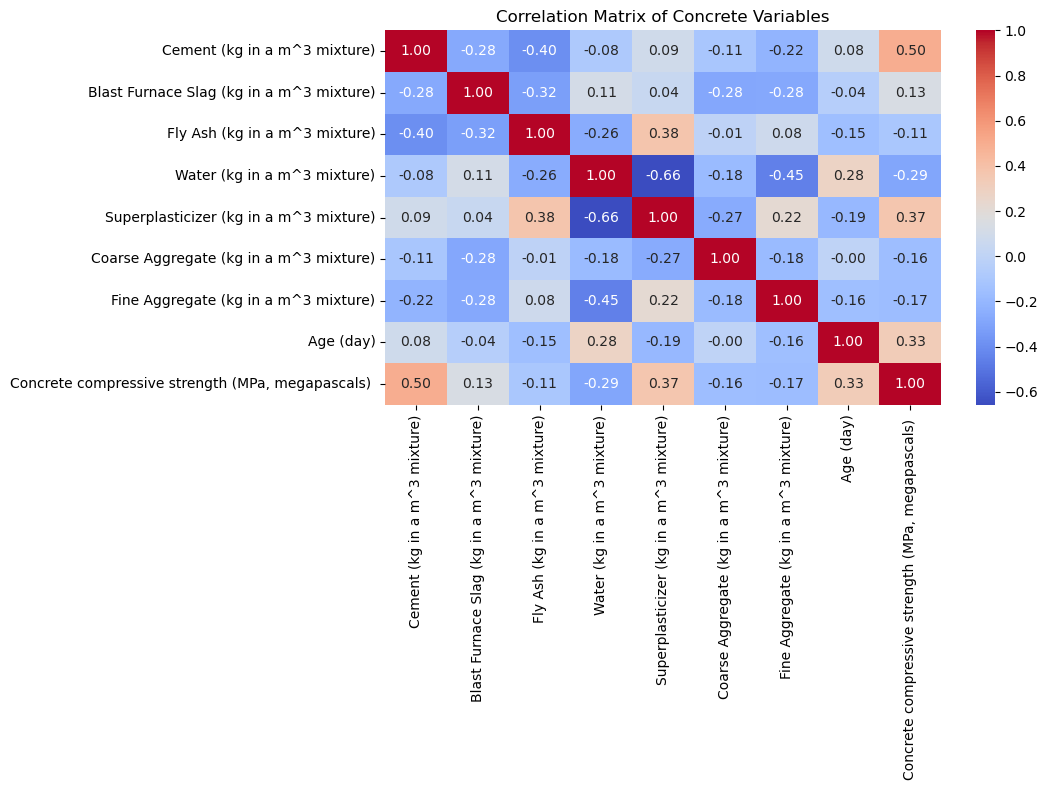

In [3]:
# Plotting distributions and correlations

# Distribution of concrete strength
plt.figure(figsize=(8, 5))

sns.histplot(df.iloc[:, -1], bins=30, kde=True)

plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Concrete Strength (MPa)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# Correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Concrete Variables")

plt.tight_layout()
plt.show()

In [4]:
# Creating a working copy of the dataset
df_clean = df.copy()

# Removing exact duplicate observations
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Original observations:", len(df))
print("Observations after cleaning:", len(df_clean))
print("Duplicates removed:", len(df) - len(df_clean))

# Separating predictors and target
X = df_clean.iloc[:, :-1]
y = df_clean.iloc[:, -1]

print("\nPredictor dimensions:", X.shape)
print("Target dimensions:", y.shape)

Original observations: 1030
Observations after cleaning: 1005
Duplicates removed: 25

Predictor dimensions: (1005, 8)
Target dimensions: (1005,)


In [5]:
from sklearn.model_selection import train_test_split

#Spliting into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 804
Testing observations: 201


In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Establishing mean-prediction baseline
baseline_model = DummyRegressor(strategy="mean")

# Training using training data only
baseline_model.fit(X_train, y_train)

# Generating test predictions
baseline_predictions = baseline_model.predict(X_test)

# Evaluating baseline
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

# Summarizing baseline performance
baseline_results = pd.DataFrame({
    "Model": ["Mean Prediction Baseline"],
    "MAE": [baseline_mae],
    "RMSE": [baseline_rmse],
    "R²": [baseline_r2]
})

print(
    "Training mean concrete strength:",
    round(y_train.mean(), 2),
    "MPa"
)

display(baseline_results.round(4))

Training mean concrete strength: 35.07 MPa


,Model,MAE,RMSE,R²
0,Mean Prediction Baseline,13.9723,17.2965,-0.0028


### 2.2 Data Preparation and Mean-Prediction Baseline

Data preparation involved removing 25 exact duplicate observations, reducing the dataset from 1,030 to 1,005 records. No missing-value imputation or categorical encoding was required because all variables were numerical and complete. Extreme observations were retained because there was insufficient evidence to classify them as erroneous.

The cleaned dataset was divided into 804 training observations (80%) and 201 testing observations (20%), using a fixed random state to ensure reproducibility.

A mean-prediction baseline was established using the average concrete compressive strength of the training dataset (35.07 MPa). The baseline achieved a Mean Absolute Error (MAE) of 13.97 MPa, Root Mean Squared Error (RMSE) of 17.30 MPa, and R² of -0.0028 on the test dataset.

These results indicate that predicting a constant mean strength provides limited predictive usefulness. The baseline therefore serves as a reference for assessing whether linear and nonlinear regression models can improve prediction accuracy.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Linear Regression pipeline
linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Random Forest Regression pipeline
rf_pipeline = Pipeline([
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    ))
])

print("Linear Regression and Random Forest pipelines created successfully.")

Linear Regression and Random Forest pipelines created successfully.


In [8]:
from sklearn.model_selection import KFold, cross_validate

# Defining five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Defining evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Models to compare
models = {
    "Linear Regression": linear_pipeline,
    "Random Forest": rf_pipeline
}

cv_results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R²": scores["test_R2"].mean(),
        "RMSE Std": scores["test_RMSE"].std()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.round(4))

,Model,MAE,RMSE,R²,RMSE Std
0,Linear Regression,8.1003,10.2027,0.5895,0.1535
1,Random Forest,4.0158,5.4900,0.8807,0.3937


### 3.1 Cross-Validation Model Comparison

Linear Regression and Random Forest Regression were evaluated using five-fold cross-validation on the training dataset.

Random Forest substantially outperformed Linear Regression, achieving a Mean Absolute Error (MAE) of 4.02 MPa compared with 8.10 MPa, and a Root Mean Squared Error (RMSE) of 5.49 MPa compared with 10.20 MPa. These represent reductions in prediction error of approximately 50.4% and 46.2%, respectively.

Random Forest also achieved a higher mean R² (0.8807) than Linear Regression (0.5895), indicating substantially better predictive performance across the validation folds.

Although Linear Regression exhibited lower variability in RMSE across folds, Random Forest demonstrated considerably greater predictive accuracy.

These findings suggest that nonlinear relationships and interactions between mixture composition, curing age, and concrete strength are important for prediction. Random Forest was therefore identified as the stronger candidate, subject to confirmation using the independent test dataset.

In [9]:
# Training both models and evaluating on the independent test dataset

test_results = []
test_predictions = {}

for model_name, model in models.items():

    # Fitting model using the complete training dataset
    model.fit(X_train, y_train)

    # Predicting concrete strength
    predictions = model.predict(X_test)

    # Save predictions for residual analysis
    test_predictions[model_name] = predictions

    # Calculating performance metrics
    test_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions)
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))

,Model,MAE,RMSE,R²
0,Linear Regression,8.8960,11.1922,0.5801
1,Random Forest,3.7361,5.3788,0.9030


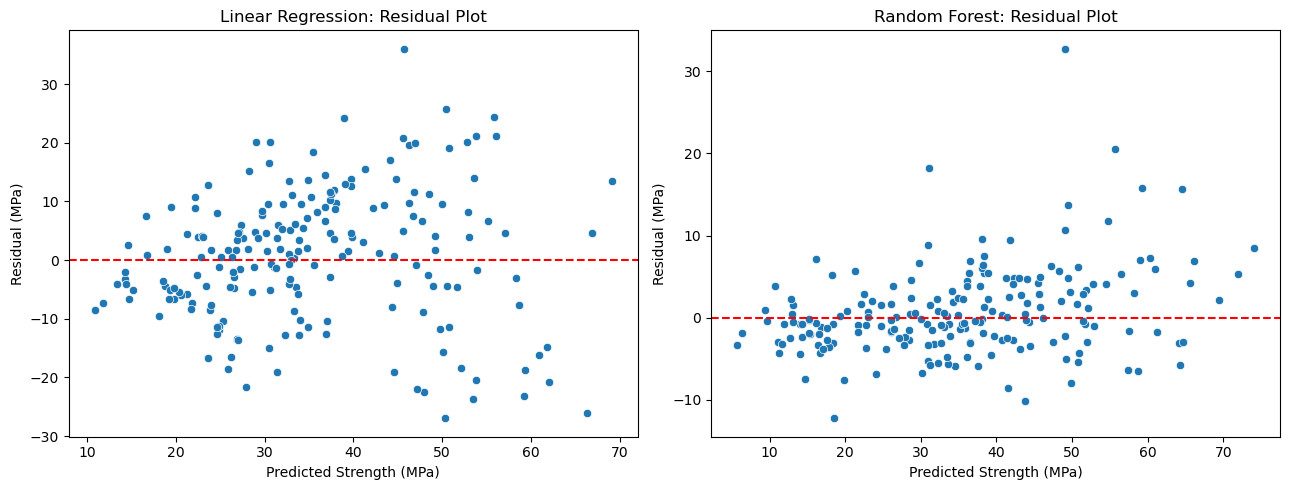

In [10]:
# Plotting residuals against predicted values

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, predictions) in zip(
    axes, test_predictions.items()
):

    residuals = y_test - predictions

    sns.scatterplot(
        x=predictions,
        y=residuals,
        ax=ax
    )

    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(f"{model_name}: Residual Plot")
    ax.set_xlabel("Predicted Strength (MPa)")
    ax.set_ylabel("Residual (MPa)")

plt.tight_layout()
plt.show()

In [11]:
# Examining prediction errors by concrete strength category

residual_df = pd.DataFrame({
    "Actual Strength": y_test.values,
    "Linear Prediction": test_predictions["Linear Regression"],
    "RF Prediction": test_predictions["Random Forest"]
})

# Calculating absolute errors
residual_df["Linear Absolute Error"] = abs(
    residual_df["Actual Strength"] -
    residual_df["Linear Prediction"]
)

residual_df["RF Absolute Error"] = abs(
    residual_df["Actual Strength"] -
    residual_df["RF Prediction"]
)

# Categorizing actual concrete strength
residual_df["Strength Category"] = pd.cut(
    residual_df["Actual Strength"],
    bins=[-np.inf, 20, 50, np.inf],
    labels=["Low (<20 MPa)", "Medium (20–50 MPa)", "High (>50 MPa)"]
)

# Calculating average absolute error by category
error_by_strength = (
    residual_df.groupby(
        "Strength Category",
        observed=True
    )
    .agg(
        Observations=("Actual Strength", "count"),
        Linear_MAE=("Linear Absolute Error", "mean"),
        RF_MAE=("RF Absolute Error", "mean")
    )
    .reset_index()
)

display(error_by_strength.round(4))

,Strength Category,Observations,Linear_MAE,RF_MAE
0,Low (<20 MPa),40,8.6442,2.6950
1,Medium (20–50 MPa),120,7.4753,3.1385
2,High (>50 MPa),41,13.3000,6.5010


### 3.2 Final Model Comparison and Residual Analysis

Linear Regression and Random Forest Regression were evaluated on an independent test dataset containing 201 observations.

Random Forest substantially outperformed Linear Regression, achieving a Mean Absolute Error (MAE) of 3.74 MPa compared with 8.90 MPa, and a Root Mean Squared Error (RMSE) of 5.38 MPa compared with 11.19 MPa. These represent reductions in prediction error of approximately 58.0% and 51.9%, respectively.

Random Forest also achieved a higher R² (0.9030) than Linear Regression (0.5801), indicating that the nonlinear approach captured substantially more variation in concrete compressive strength. Both models outperformed the mean-prediction baseline, which recorded an RMSE of 17.30 MPa.

Residual analysis revealed that Linear Regression exhibited greater dispersion around zero, with several prediction errors exceeding ±20 MPa. Random Forest residuals were more tightly concentrated around zero, although occasional substantial underestimations remained.

Analysis by strength category revealed that both models performed worst on high-strength concrete exceeding 50 MPa. Linear Regression recorded an MAE of 13.30 MPa in this category, compared with 6.50 MPa for Random Forest. In contrast, Random Forest achieved MAEs of 2.70 MPa and 3.14 MPa for low- and medium-strength concrete, respectively.

These findings suggest that nonlinear relationships and interactions are important for predicting concrete compressive strength. However, prediction accuracy varies across strength categories, with high-strength mixtures presenting the greatest difficulties.

Random Forest was therefore selected as the preferred predictive approach, although additional validation would be advisable before applying the model to engineering decisions.

## 4. Predictive Association Versus Causation

A predictive association between cement content and concrete compressive strength does not necessarily establish what would happen if cement content were changed in a real-world mixture.

The exploratory analysis revealed a moderate positive correlation (r = 0.50) between cement content and compressive strength, indicating that mixtures containing more cement generally exhibited higher strength in the observed dataset.

However, concrete strength depends on multiple interacting factors, including water content, supplementary cementitious materials, aggregates, and curing age. These factors may confound the observed relationship between cement content and strength.

Furthermore, the relationship may be nonlinear, meaning that increasing cement content does not necessarily produce a constant or proportional increase in compressive strength.

Although Random Forest demonstrated strong predictive performance (R² = 0.9030), this establishes predictive accuracy on the test dataset rather than a causal effect of cement content.

Establishing causation would require controlled experiments or an appropriate causal inference design in which cement content is systematically varied while relevant mixture characteristics and curing conditions are controlled.

Therefore, the model is suitable for predicting strength within the range of observed mixtures but should not be used alone to determine the consequences of changing concrete composition.

## 5. Conclusion

This project investigated the prediction of concrete compressive strength using mixture composition and curing age.

Exploratory analysis identified meaningful associations between compressive strength and several predictors, particularly cement content, superplasticizer, and curing age.

Following data preparation, a mean-prediction baseline and two regression approaches were evaluated. Random Forest substantially outperformed Linear Regression, achieving an independent test RMSE of 5.38 MPa and R² of 0.9030.

Residual analysis revealed that prediction errors were greatest for high-strength concrete exceeding 50 MPa, although Random Forest consistently outperformed Linear Regression across all examined strength categories.

The findings demonstrate the predictive value of nonlinear modeling approaches for concrete strength estimation. However, predictive associations do not establish causal effects, and controlled experimentation would be required to determine the consequences of modifying concrete mixture compositions.

Random Forest is therefore recommended as the preferred predictive model, subject to further validation before practical engineering application.